In [47]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
preprocessor = joblib.load("../models/preprocessor.pkl")

In [48]:
X_train=pd.read_csv("../data/processed-data/x_train_data.csv")
X_test=pd.read_csv("../data/processed-data/x_test_data.csv")
y_train=pd.read_csv("../data/processed-data/y_train_data.csv")
y_test=pd.read_csv("../data/processed-data/y_test_data.csv")

In [49]:
#for tenure and Monthlycharge skewness increase

0.9686903650242794
0.30516696511507746


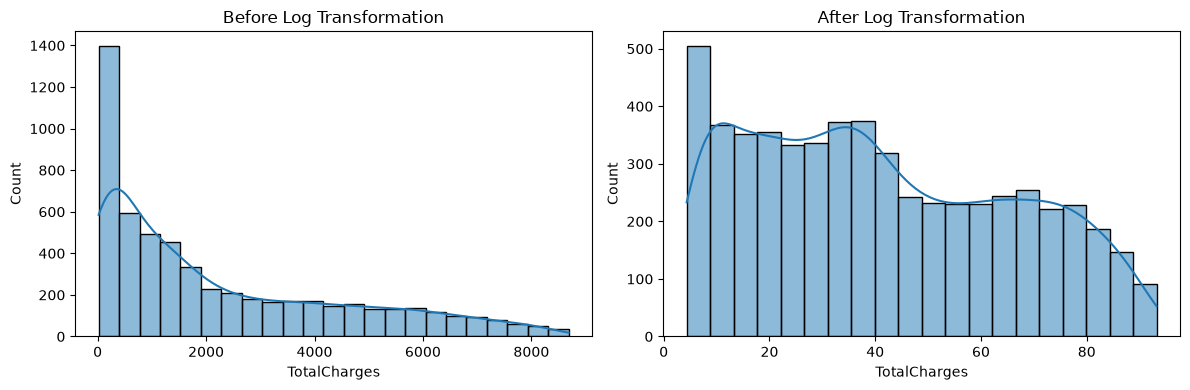

In [50]:
total = np.sqrt(X_train["TotalCharges"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X_train["TotalCharges"], kde=True, ax=axes[0],stat="count")
axes[0].set_title("Before Log Transformation")

sns.histplot(total, kde=True, ax=axes[1],stat="count")
axes[1].set_title("After Log Transformation")
print(X_train["TotalCharges"].skew())
print(total.skew())
plt.tight_layout()
plt.show()

In [51]:
print(X_train["TotalCharges"].skew())
print(total.skew())

0.9686903650242794
0.30516696511507746


In [52]:
X_train["TotalCharges"]=np.sqrt(X_train["TotalCharges"])
X_test["TotalCharges"]=np.sqrt(X_test["TotalCharges"])

In [53]:
from sklearn.pipeline import Pipeline
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

model_pipeline.fit(X_train, y_train)
y_pred=model_pipeline.predict(X_test)


c:\Users\dell\.anaconda-desktop\micromamba\envs\assistant\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.7782515991471215
Precision: 0.6040268456375839
Recall: 0.48128342245989303
F1 Score: 0.5357142857142857
              precision    recall  f1-score   support

           0       0.83      0.89      0.85      1033
           1       0.60      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.71      0.68      0.70      1407
weighted avg       0.77      0.78      0.77      1407



In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))


Accuracy: 0.7782515991471215
Precision: 0.6040268456375839
Recall: 0.48128342245989303
F1 Score: 0.5357142857142857


In [58]:
X_train.describe()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges
count,5625.000000,5625.000000,5625.000000,5625.000000,5625.000000,5625.000000,5625.000000,5625.000000
mean,0.163200,0.480356,0.298667,32.375822,0.903111,0.592000,64.283911,41.007781
std,0.369581,0.499658,0.457714,24.484324,0.295833,0.491507,30.022240,24.491128
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,18.000000,4.341659
25%,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,35.000000,20.032474
50%,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,70.000000,37.496667
75%,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,89.000000,61.465437
max,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,118.000000,93.192274


In [57]:
from sklearn.decomposition import PCA

pca_model = Pipeline([
    ("preprocessor", preprocessor),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=1000))
])
pca_model.fit(X_train, y_train)
# Train
pca_model.fit(X_train, y_train)

# Predict
y_pred_custom = pca_model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred_custom))
print("Precision:", precision_score(y_test, y_pred_custom))
print("Recall:", recall_score(y_test, y_pred_custom))
print("F1 score:", f1_score(y_test, y_pred_custom))

Accuracy: 0.7690120824449183
Precision: 0.5847750865051903
Recall: 0.45187165775401067
F1 score: 0.5098039215686274


c:\Users\dell\.anaconda-desktop\micromamba\envs\assistant\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\dell\.anaconda-desktop\micromamba\envs\assistant\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
# Reasult:
# No change after scaling then no requirement for scaling
#No diff in accuracy after pca